# Graph Theory, Graph Laplacians, and Graph Neural Networks

**AI Mathematics · 7. Advanced Topics**

Connect adjacency matrices, degrees, Laplacians, and message-passing operations used in graph learning.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Represent a graph with an adjacency matrix.
- Calculate degree and graph Laplacian matrices.
- Understand a simple graph convolution/message-passing step.

In [1]:
import numpy as np

## 1. Graph representation
A graph consists of nodes and edges. For an undirected unweighted graph, its adjacency matrix \(A\) is symmetric with \(A_{ij}=1\) when nodes \(i\) and \(j\) are connected. Weighted graphs store edge weights; directed graphs need not have symmetric adjacency matrices.

In [2]:
import numpy as np

A = np.array([[0, 1, 1, 0],
              [1, 0, 1, 1],
              [1, 1, 0, 0],
              [0, 1, 0, 0]], dtype=float)
print("adjacency:\n", A)
print("undirected:", np.allclose(A, A.T))
print("degrees:", A.sum(axis=1))

adjacency:
 [[0. 1. 1. 0.]
 [1. 0. 1. 1.]
 [1. 1. 0. 0.]
 [0. 1. 0. 0.]]
undirected: True
degrees: [2. 3. 2. 1.]


## 2. Graph Laplacian
The unnormalized graph Laplacian is \(L=D-A\), where \(D\) is the diagonal degree matrix. For an undirected nonnegative graph, \(L\) is positive semidefinite. Its eigenvalues describe graph connectivity and are used in spectral clustering and graph signal processing.

In [3]:
D = np.diag(A.sum(axis=1))
L = D - A
print("Laplacian:\n", L)
print("L symmetric:", np.allclose(L, L.T))
print("L eigenvalues:", np.linalg.eigvalsh(L))

Laplacian:
 [[ 2. -1. -1.  0.]
 [-1.  3. -1. -1.]
 [-1. -1.  2.  0.]
 [ 0. -1.  0.  1.]]
L symmetric: True
L eigenvalues: [-8.32667268e-16  1.00000000e+00  3.00000000e+00  4.00000000e+00]


## 3. Smoothness on a graph
For scalar node values \(x\), the quantity \(x^TLx\) equals a sum of squared differences over edges for an undirected unweighted graph. It is small when neighboring nodes have similar values. This is useful for graph signals, but smoothing can blur meaningful boundaries.

In [4]:
node_values = np.array([1.0, 1.2, 0.9, 3.0])
energy = node_values @ L @ node_values
print("graph smoothness energy:", energy)

# Compare with a more locally consistent assignment.
node_values_smooth = np.array([1.0, 1.1, 1.0, 1.2])
print("smoothed energy:", node_values_smooth @ L @ node_values_smooth)

graph smoothness energy: 3.38
smoothed energy: 0.030000000000000006


## 4. A simple message-passing layer
A graph neural network updates each node representation using information aggregated from neighboring nodes. One simplified normalized graph convolution is \(H^{(l+1)}=\sigma(\tilde D^{-1/2}\tilde A\tilde D^{-1/2}H^{(l)}W)\), where self-loops are added to \(A\). Real GNN variants differ in normalization, aggregation, and training objective.

In [5]:
A_tilde = A + np.eye(A.shape[0])
D_tilde = np.diag(A_tilde.sum(axis=1))
D_inv_sqrt = np.diag(1.0 / np.sqrt(np.diag(D_tilde)))
A_norm = D_inv_sqrt @ A_tilde @ D_inv_sqrt
H = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0], [2.0, 1.0]])
W = np.array([[0.5, -0.2], [0.3, 0.8]])
H_next = np.maximum(0, A_norm @ H @ W)  # ReLU activation
print("new node features:\n", H_next)

new node features:
 [[0.51993587 0.36427344]
 [0.90989708 0.45689141]
 [0.51993587 0.36427344]
 [0.75606602 0.48284271]]


## 5. Normalized Laplacians and caveats
The symmetric normalized Laplacian is \(L_{sym}=I-D^{-1/2}AD^{-1/2}\) for nodes with nonzero degree. Isolated nodes need special treatment. Graph construction matters: missing edges, false edges, and arbitrary weights can materially change what a GNN learns.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: adjacency, edges, and the graph Laplacian

An adjacency matrix records which nodes are connected. The degree matrix records each node's total edge weight, and the unnormalized Laplacian is \(L=D-A\). For an undirected graph with nonnegative weights, the Laplacian is symmetric positive semidefinite; its eigenvalues reveal connectivity structure.

Laplacian eigenvalues: [-0.       0.51881  2.31111  3.       4.17009]


21_graph_theory_laplacian_and_gnns.ipynb:cell14:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,A,B,C,D,E
A,0.0,1.0,1.0,0.0,0.0
B,1.0,0.0,1.0,1.0,0.0
C,1.0,1.0,0.0,0.0,0.0
D,0.0,1.0,0.0,0.0,1.0
E,0.0,0.0,0.0,1.0,0.0


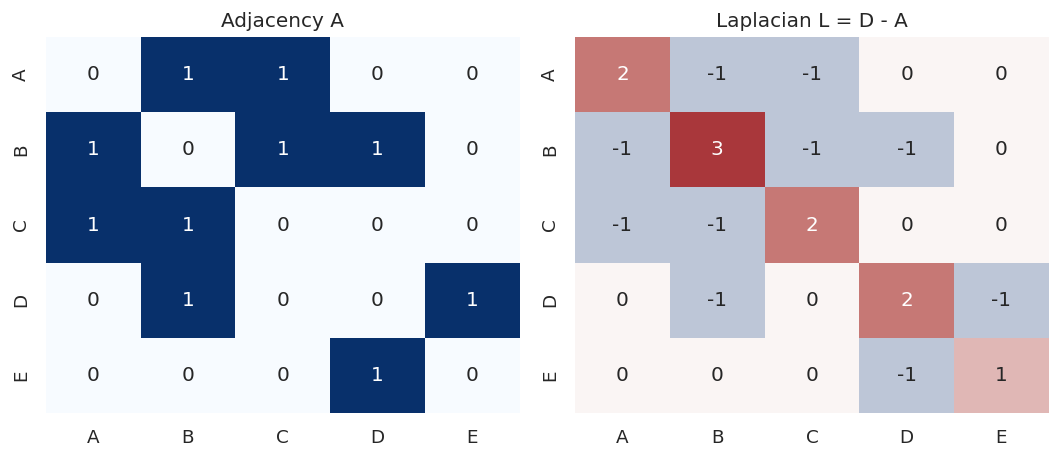

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_graph_names = ["A", "B", "C", "D", "E"]
viz_graph_A = np.array([[0,1,1,0,0], [1,0,1,1,0], [1,1,0,0,0], [0,1,0,0,1], [0,0,0,1,0]], dtype=float)
viz_graph_D = np.diag(viz_graph_A.sum(axis=1))
viz_graph_L = viz_graph_D-viz_graph_A
display(pd.DataFrame(viz_graph_A, index=viz_graph_names, columns=viz_graph_names))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
sns.heatmap(viz_graph_A, annot=True, cmap="Blues", cbar=False, xticklabels=viz_graph_names, yticklabels=viz_graph_names, ax=axes[0])
axes[0].set_title("Adjacency A")
sns.heatmap(viz_graph_L, annot=True, cmap="vlag", center=0, cbar=False, xticklabels=viz_graph_names, yticklabels=viz_graph_names, ax=axes[1])
axes[1].set_title("Laplacian L = D - A")
plt.tight_layout(); plt.show()
print("Laplacian eigenvalues:", np.round(np.linalg.eigvalsh(viz_graph_L), 5))

### Draw a small graph and inspect node messages

A simple graph drawing helps map matrix entries to edges. In a basic message-passing layer, each node aggregates information from its neighbors. Real GNN layers may normalize the adjacency, include self-loops, use learned transformations, and apply nonlinearities.

21_graph_theory_laplacian_and_gnns.ipynb:cell16:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,node,own feature,neighbor mean
0,A,1.0,3.000000
1,B,2.0,4.333333
2,C,4.0,1.500000
3,D,8.0,6.000000
4,E,10.0,8.000000


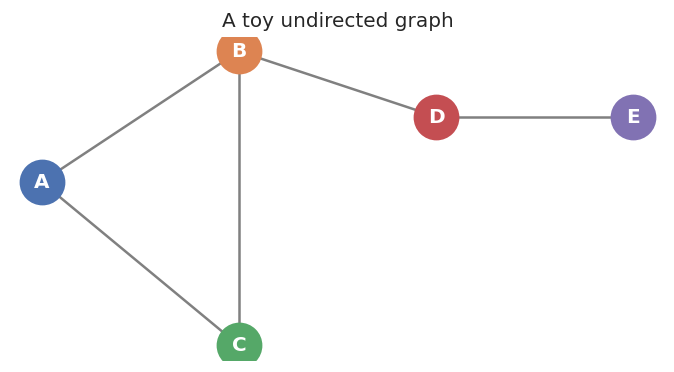

In [7]:
viz_graph_pos = {"A": (0,1), "B": (1,1.4), "C": (1,0.5), "D": (2,1.2), "E": (3,1.2)}
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, n1 in enumerate(viz_graph_names):
    for j, n2 in enumerate(viz_graph_names):
        if j > i and viz_graph_A[i,j] > 0:
            ax.plot([viz_graph_pos[n1][0], viz_graph_pos[n2][0]], [viz_graph_pos[n1][1], viz_graph_pos[n2][1]], color="0.5", zorder=1)
for name, (px, py) in viz_graph_pos.items():
    ax.scatter(px, py, s=700, zorder=2); ax.text(px, py, name, color="white", ha="center", va="center", weight="bold", zorder=3)
ax.axis("off"); ax.set_title("A toy undirected graph"); plt.show()
viz_graph_features = np.array([[1.0],[2.0],[4.0],[8.0],[10.0]])
viz_graph_neighbor_mean = (viz_graph_A @ viz_graph_features) / np.maximum(viz_graph_A.sum(axis=1, keepdims=True), 1)
display(pd.DataFrame({"node": viz_graph_names, "own feature": viz_graph_features.ravel(), "neighbor mean": viz_graph_neighbor_mean.ravel()}))

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Calculate the degree vector for a 3-node path graph.

In [8]:
A = np.array([[0,1,0],[1,0,1],[0,1,0]], dtype=float)
print(A.sum(axis=1))

[1. 2. 1.]


### Exercise 2
Exercise 2: Verify that L = D-A is positive semidefinite for the small undirected graph above.

In [9]:
D = np.diag(A.sum(axis=1)); L = D-A
print(np.linalg.eigvalsh(L))

[3.92505363e-17 1.00000000e+00 3.00000000e+00]


## Key takeaways
- Adjacency records connectivity; degree summarizes each node’s connections.
- The graph Laplacian encodes graph smoothness and has nonnegative eigenvalues for undirected nonnegative graphs.
- GNNs repeatedly aggregate transformed neighbor information, so graph construction strongly affects outcomes.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.